<a href="https://colab.research.google.com/github/fuadsaniibrahim/FIP-Intern-Deliverable/blob/main/module-1/Module1_Ensemble_and_XAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 1: Advanced Machine Learning Techniques

**Techniques demonstrated:** (1) Ensemble Learning (Random Forest and Gradient Boosting) and (2) Explainable AI (SHAP and LIME).

**Problem:** classify breast tumours as malignant or benign from 30 numeric features computed from cell nucleus images (Wisconsin Diagnostic Breast Cancer dataset, bundled with scikit-learn).

**Plan**
1. Load data and create train / validation / test splits
2. Train baselines (logistic regression, single decision tree)
3. Train ensembles (Random Forest = bagging, XGBoost = boosting) and compare them with the baselines
4. Tune the boosting model
5. Evaluate once on the held-out test set
6. Explain the final model with SHAP (global and local) and LIME (local), then compare the explanations
7. Discuss findings and limitations

In [3]:
!pip install -q lime shap xgboost

## 1. Setup and data

In [4]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier
import shap

from lime.lime_tabular import LimeTabularExplainer

SEED = 42
np.random.seed(SEED)

data = load_breast_cancer(as_frame=True)
X = data.data
y = 1 - data.target          # flip so that 1 = malignant (the class we most care about catching)
print(X.shape, "| malignant share: %.1f%%" % (100*y.mean()))
X.head(3)

(569, 30) | malignant share: 37.3%


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


### Splits
A 60/20/20 stratified split. The **validation set** is used to compare models and pick the winner. The **test set** is touched once at the end so the final number is an honest estimate.

In [5]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
for n, a in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{n:5s} n={len(a):3d}  malignant={a.mean():.2%}")

train n=341  malignant=37.24%
val   n=114  malignant=37.72%
test  n=114  malignant=36.84%


## 2. Baselines
Ensembles only mean something relative to simpler models. Two baselines: a scaled logistic regression (strong linear baseline) and one unpruned decision tree (the weak learner that ensembles are built from).

In [6]:
def scores(model, Xs, ys):
    p = model.predict_proba(Xs)[:, 1]
    yhat = (p >= 0.5).astype(int)
    return dict(accuracy=accuracy_score(ys, yhat), precision=precision_score(ys, yhat),
                recall=recall_score(ys, yhat), f1=f1_score(ys, yhat), roc_auc=roc_auc_score(ys, p))

models = {
    "Logistic Regression (baseline)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)),
    "Decision Tree (baseline)": DecisionTreeClassifier(random_state=SEED),
    "Random Forest (bagging)": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "XGBoost (boosting)": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                        eval_metric="logloss", random_state=SEED, n_jobs=-1),
}
for m in models.values():
    m.fit(X_train, y_train)

val_table = pd.DataFrame({n: scores(m, X_val, y_val) for n, m in models.items()}).T.round(3)
val_table

,accuracy,precision,recall,f1,roc_auc
Logistic Regression (baseline),0.974,0.955,0.977,0.966,0.996
Decision Tree (baseline),0.904,0.848,0.907,0.876,0.904
Random Forest (bagging),0.974,0.976,0.953,0.965,0.992
XGBoost (boosting),0.965,0.953,0.953,0.953,0.993


### Cross-validation check
A single validation split of 114 patients is small, so one lucky split could mislead. Stratified 5-fold CV on the training data gives a mean and spread for each model.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = {}
for n, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    rows[n] = dict(cv_auc_mean=s.mean(), cv_auc_std=s.std())
pd.DataFrame(rows).T.round(4)

,cv_auc_mean,cv_auc_std
Logistic Regression (baseline),0.9941,0.0078
Decision Tree (baseline),0.9364,0.0180
Random Forest (bagging),0.9860,0.0149
XGBoost (boosting),0.9916,0.0102


### Why the ensembles help (variance reduction)

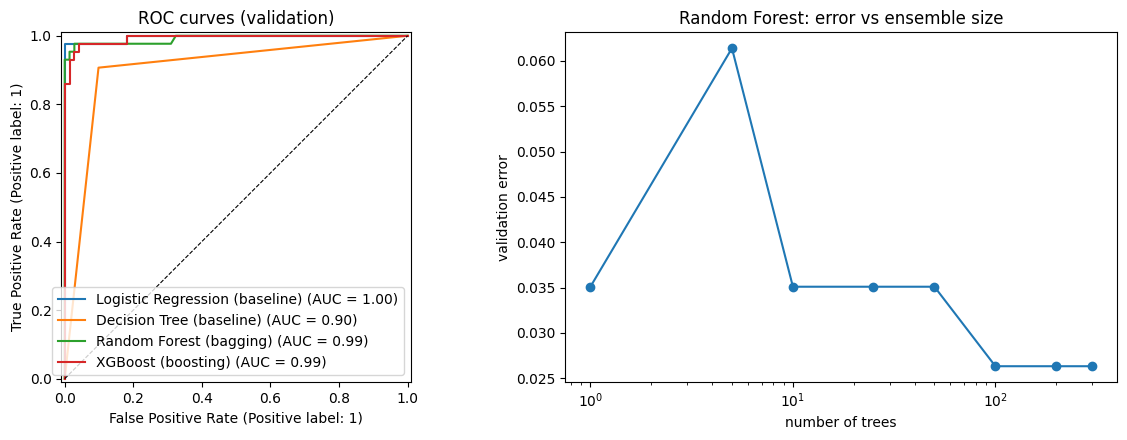

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, m in models.items():
    RocCurveDisplay.from_estimator(m, X_val, y_val, ax=ax[0], name=n)
ax[0].set_title("ROC curves (validation)")
ax[0].plot([0,1],[0,1],"k--",lw=0.8)

# error vs number of trees for the Random Forest: more trees -> lower, stabler error
rf_curve = []
for k in [1, 5, 10, 25, 50, 100, 200, 300]:
    rf = RandomForestClassifier(n_estimators=k, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    rf_curve.append((k, 1 - accuracy_score(y_val, rf.predict(X_val))))
ks, errs = zip(*rf_curve)
ax[1].plot(ks, errs, marker="o"); ax[1].set_xscale("log")
ax[1].set_xlabel("number of trees"); ax[1].set_ylabel("validation error")
ax[1].set_title("Random Forest: error vs ensemble size")
plt.tight_layout(); plt.show()

## 3. Tune the boosting model
Random search over the main XGBoost knobs, scored by ROC-AUC with 5-fold CV on the **training set only**. Validation is then used to confirm that tuning actually helped, because tuning can overfit the CV folds.

In [9]:
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5, 6],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_lambda": [0.5, 1, 2, 5],
}
search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1),
    param_dist, n_iter=30, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
print("best params:", search.best_params_)
print("best CV AUC: %.4f" % search.best_score_)

tuned = search.best_estimator_
cmp = pd.DataFrame({"XGBoost default": scores(models["XGBoost (boosting)"], X_val, y_val),
                    "XGBoost tuned": scores(tuned, X_val, y_val)}).T.round(3)
cmp

best params: {'subsample': 0.8, 'reg_lambda': 2, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
best CV AUC: 0.9921


,accuracy,precision,recall,f1,roc_auc
XGBoost default,0.965,0.953,0.953,0.953,0.993
XGBoost tuned,0.965,0.953,0.953,0.953,0.993


## 4. Final evaluation on the test set
The model with the best validation result is chosen **before** looking at the test set. The selection is made in code below so it is reproducible.

validation AUC: {'Logistic Regression (baseline)': np.float64(0.9957), 'Decision Tree (baseline)': np.float64(0.9042), 'Random Forest (bagging)': np.float64(0.9916), 'XGBoost (boosting)': np.float64(0.9931), 'XGBoost (tuned)': np.float64(0.9928)}
selected: Logistic Regression (baseline)
tree ensemble used for explanations: XGBoost (boosting)


,accuracy,precision,recall,f1,roc_auc
Logistic Regression (baseline),0.974,0.976,0.952,0.964,0.995
Decision Tree (baseline),0.904,0.897,0.833,0.864,0.889
Random Forest (bagging),0.956,0.974,0.905,0.938,0.997
XGBoost (boosting),0.965,1.000,0.905,0.950,0.993
XGBoost (tuned),0.982,1.000,0.952,0.976,0.995


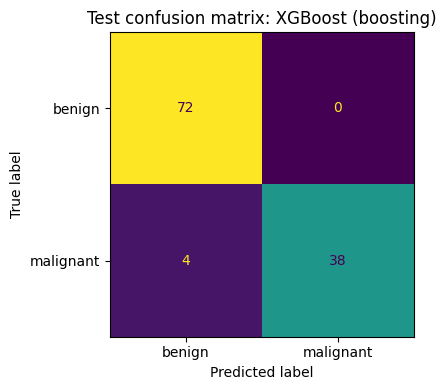

In [10]:
candidates = {**models, "XGBoost (tuned)": tuned}
val_auc = {n: roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]) for n, m in candidates.items()}
best_name = max(val_auc, key=val_auc.get)
print("validation AUC:", {k: round(v, 4) for k, v in val_auc.items()})
print("selected:", best_name)

# the explanation section uses a tree-based model, so pick the best tree ensemble for SHAP
tree_names = [n for n in candidates if "Random Forest" in n or "XGBoost" in n]
final_name = max(tree_names, key=val_auc.get)
final = candidates[final_name]
print("tree ensemble used for explanations:", final_name)

test_table = pd.DataFrame({n: scores(m, X_test, y_test) for n, m in candidates.items()}).T.round(3)
display(test_table)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(final, X_test, y_test, display_labels=["benign", "malignant"], ax=ax, colorbar=False)
ax.set_title(f"Test confusion matrix: {final_name}"); plt.tight_layout(); plt.show()

In a medical screening setting a **false negative** (a malignant tumour predicted benign) is far more costly than a false positive, so recall on the malignant class matters more than raw accuracy here. That is why precision, recall and AUC are reported alongside accuracy.

## 5. Explainable AI

High accuracy is not enough when predictions affect people. Two complementary tools are used:

* **SHAP** assigns each feature a contribution to each prediction using Shapley values from cooperative game theory. It gives both global and local explanations.
* **LIME** fits a simple local linear model on perturbed copies of a single instance. It is quick and model agnostic but is local only and can vary between runs.

### Worked example: Shapley values by hand
Two features A and B. Let v(S) be the model output when only the features in S are known. Assume

* v(empty) = 0.50 (base rate)
* v({A}) = 0.70
* v({B}) = 0.60
* v({A,B}) = 0.90 (full prediction)

Each feature's Shapley value is its average marginal contribution over both orderings of adding features.

```
phi_A = 1/2 [ v({A}) - v({}) ] + 1/2 [ v({A,B}) - v({B}) ]
      = 1/2 (0.70 - 0.50)      + 1/2 (0.90 - 0.60)
      = 1/2 (0.20)             + 1/2 (0.30)
      = 0.10                   + 0.15
      = 0.25

phi_B = 1/2 [ v({B}) - v({}) ] + 1/2 [ v({A,B}) - v({A}) ]
      = 1/2 (0.60 - 0.50)      + 1/2 (0.90 - 0.70)
      = 1/2 (0.10)             + 1/2 (0.20)
      = 0.05                   + 0.10
      = 0.15

Check (efficiency):  base + phi_A + phi_B = 0.50 + 0.25 + 0.15 = 0.90 = v({A,B})
```
The contributions add up exactly to the prediction. SHAP does this for every feature of every row, using fast tree algorithms for tree ensembles.

### 5.1 SHAP: global view

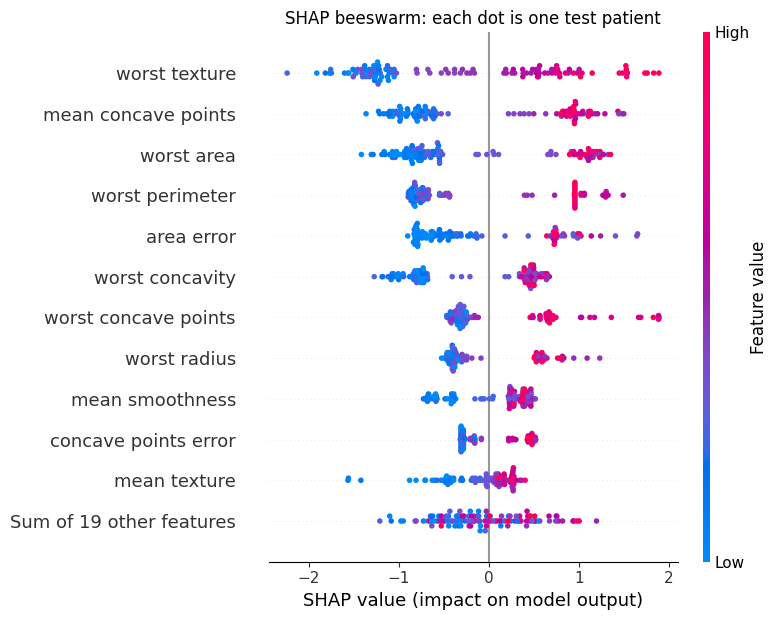

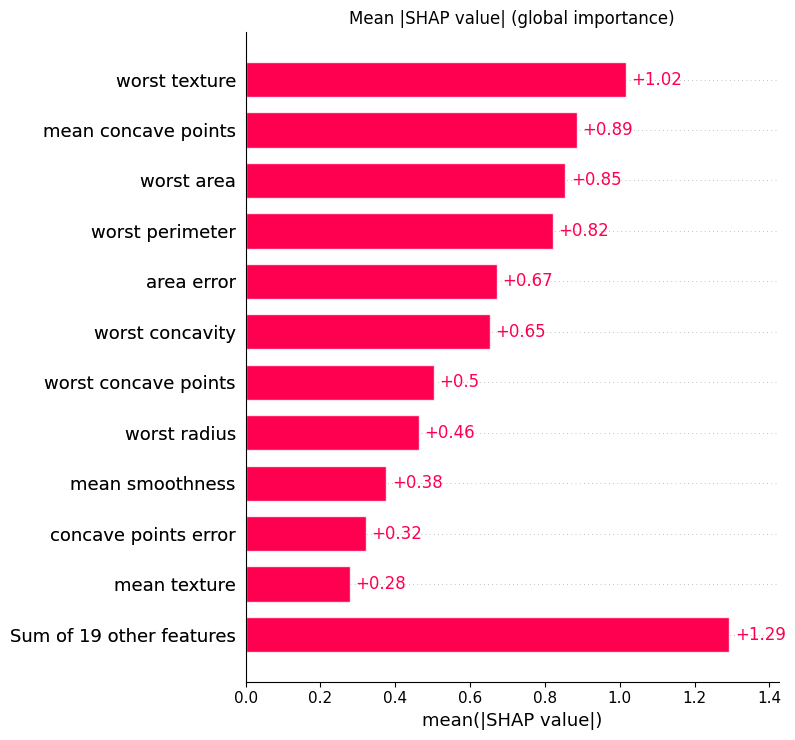

In [11]:
explainer = shap.TreeExplainer(final)
sv = explainer(X_test)
# Random Forest returns one set of values per class; keep the malignant class
if sv.values.ndim == 3:
    sv = sv[:, :, 1]

plt.figure(); shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP beeswarm: each dot is one test patient"); plt.tight_layout(); plt.show()

plt.figure(); shap.plots.bar(sv, max_display=12, show=False)
plt.title("Mean |SHAP value| (global importance)"); plt.tight_layout(); plt.show()

### 5.2 SHAP: local view (one prediction)

most confident malignant: test row 22, P(malignant)=1.000, true label=1


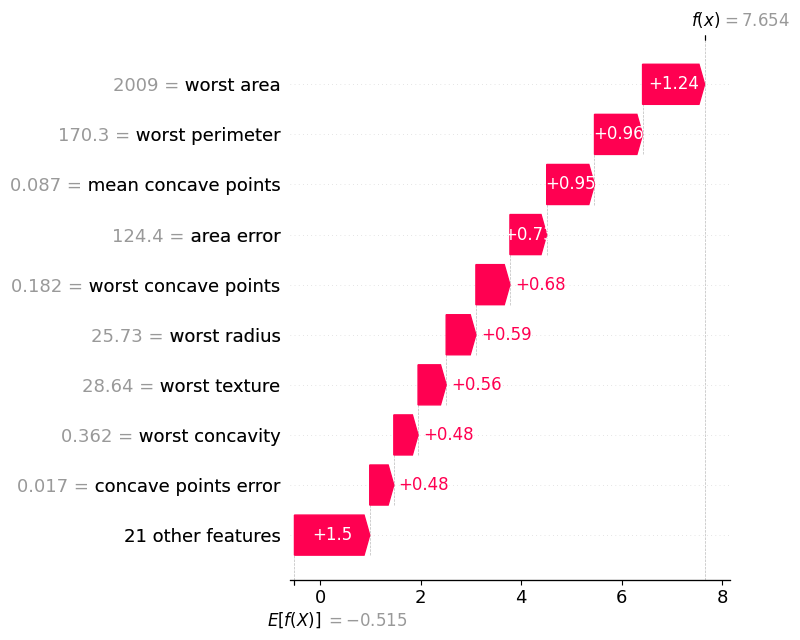

closest to the decision boundary: test row 112, P(malignant)=0.468, true label=1


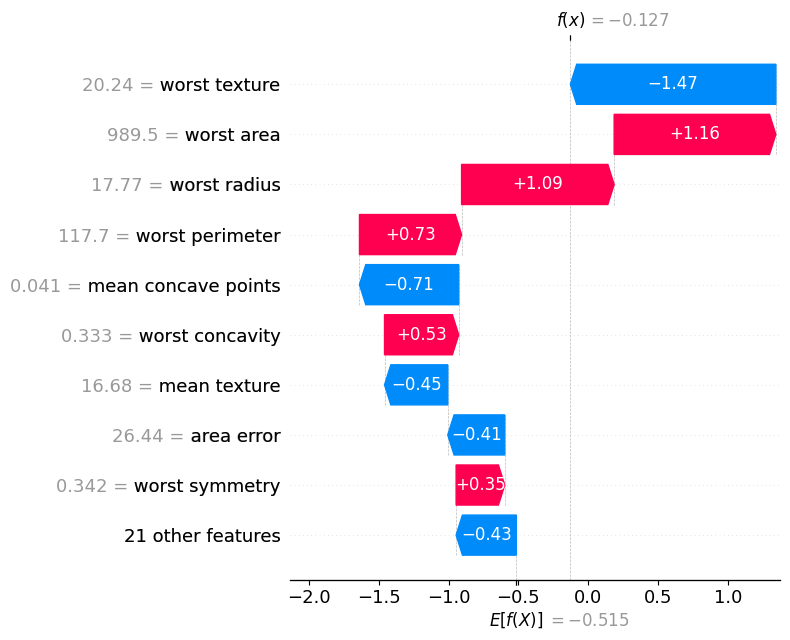

In [12]:
proba = final.predict_proba(X_test)[:, 1]
i = int(np.argmax(proba))           # most confidently malignant case
j = int(np.argmin(np.abs(proba - 0.5)))   # the most uncertain case
for name, idx in [("most confident malignant", i), ("closest to the decision boundary", j)]:
    print(f"{name}: test row {idx}, P(malignant)={proba[idx]:.3f}, true label={y_test.iloc[idx]}")
    plt.figure(); shap.plots.waterfall(sv[idx], max_display=10, show=False)
    plt.tight_layout(); plt.show()

### 5.3 SHAP dependence: how a single feature moves the prediction

<Figure size 640x480 with 0 Axes>

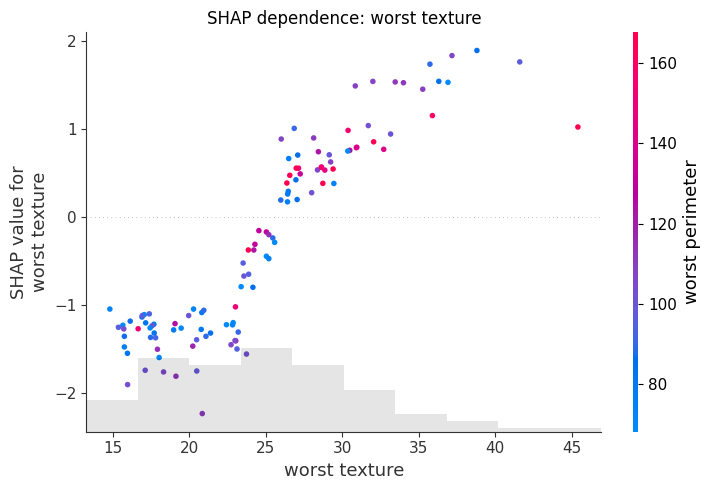

<Figure size 640x480 with 0 Axes>

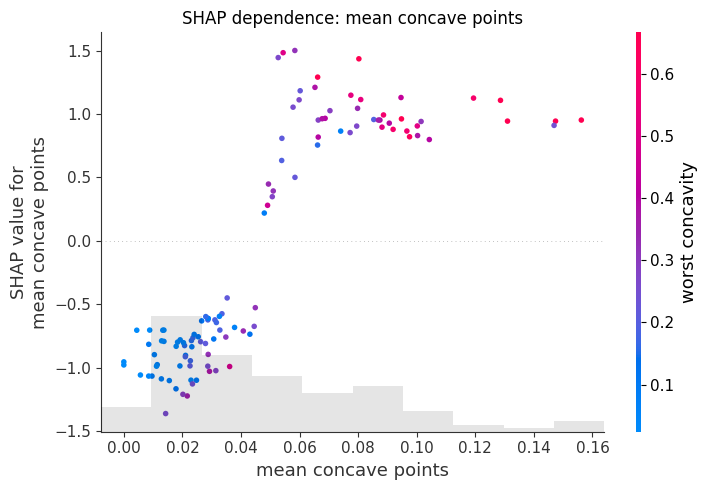

In [13]:
top = X.columns[np.argsort(np.abs(sv.values).mean(0))[::-1]][:2]
for f in top:
    plt.figure(); shap.plots.scatter(sv[:, f], color=sv, show=False)
    plt.title(f"SHAP dependence: {f}"); plt.tight_layout(); plt.show()

### 5.4 LIME: local explanation of the same uncertain case

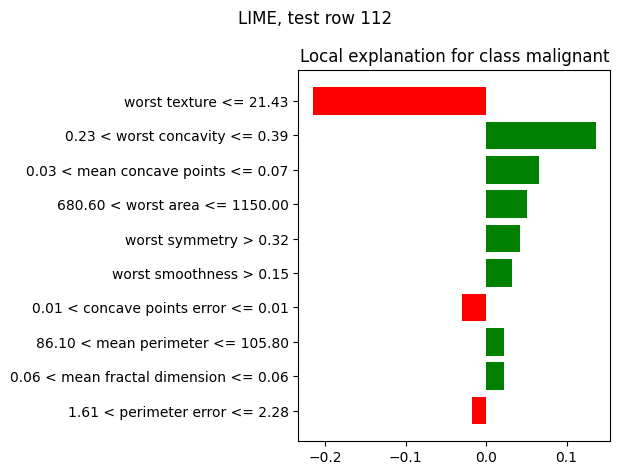

In [14]:
lime_exp = LimeTabularExplainer(X_train.values, feature_names=list(X.columns),
                                class_names=["benign", "malignant"], mode="classification",
                                discretize_continuous=True, random_state=SEED)
exp = lime_exp.explain_instance(X_test.iloc[j].values, final.predict_proba, num_features=10, num_samples=5000)
fig = exp.as_pyplot_figure(); fig.suptitle(f"LIME, test row {j}"); plt.tight_layout(); plt.show()

### 5.5 Do SHAP and LIME agree?

In [15]:
shap_top = pd.Series(sv.values[j], index=X.columns).abs().sort_values(ascending=False).head(10).index.tolist()
lime_feats = []
for rule, w in exp.as_list():
    for c in X.columns:
        if c in rule:
            lime_feats.append(c); break
lime_top = list(dict.fromkeys(lime_feats))
overlap = set(shap_top) & set(lime_top)
print("SHAP top 10 :", shap_top)
print("LIME top    :", lime_top)
print(f"overlap     : {len(overlap)} features -> {sorted(overlap)}")

# global sanity check: does SHAP importance agree with the model's built-in importance?
rf_imp = pd.Series(final.feature_importances_, index=X.columns).rank(ascending=False)
sh_imp = pd.Series(np.abs(sv.values).mean(0), index=X.columns).rank(ascending=False)
from scipy.stats import spearmanr
print("Spearman rank correlation, built-in vs SHAP importance: %.3f" % spearmanr(rf_imp, sh_imp)[0])

SHAP top 10 : ['worst texture', 'worst area', 'worst radius', 'worst perimeter', 'mean concave points', 'worst concavity', 'mean texture', 'area error', 'worst symmetry', 'mean concavity']
LIME top    : ['worst texture', 'worst concavity', 'mean concave points', 'worst area', 'worst symmetry', 'worst smoothness', 'concave points error', 'mean perimeter', 'mean fractal dimension', 'perimeter error']
overlap     : 5 features -> ['mean concave points', 'worst area', 'worst concavity', 'worst symmetry', 'worst texture']
Spearman rank correlation, built-in vs SHAP importance: 0.698


## 6. Findings and discussion

**Ensemble learning**
* A single decision tree is a high-variance learner (validation AUC 0.904, CV AUC 0.936 with the widest spread of 0.018). Averaging many decorrelated trees (Random Forest) or fitting trees sequentially on previous errors (XGBoost) lifted CV AUC to 0.986 and 0.992, and the error curve in section 2 flattens as trees are added. This is the variance reduction that ensembles are meant to deliver.
* The scaled logistic regression baseline was **as good as or better than both ensembles** (CV AUC 0.994, validation AUC 0.996). This dataset is close to linearly separable once features are scaled, so the extra flexibility of trees buys nothing. This is a legitimate result and worth reporting honestly: ensembles are not automatically better, and the baseline is what shows that.
* Tuning XGBoost with 30 random-search iterations left CV AUC essentially unchanged (0.9916 default vs 0.9921 tuned) and left validation metrics identical (accuracy 0.965 and AUC 0.993 for both), so there is no evidence that tuning helped here. The default settings were already near the ceiling.
* The test set has 114 patients, so one patient is worth about 0.9 percentage points of accuracy. The differences between the top models on test (for example 0.965 for default XGBoost vs 0.982 for tuned XGBoost, a gap of two patients) are within that noise and should not be presented as a ranking. Model selection was done on validation only.

**Explainable AI**
* The SHAP global ranking is led by worst texture, mean concave points, worst area, worst perimeter, area error and worst concavity. These describe the size and irregular shape of the cell nuclei, which is consistent with how malignancy is assessed clinically, so the model is relying on sensible signals.
* On the most uncertain test case (row 112, predicted probability of malignancy 0.468), SHAP and LIME shared 5 of their top 10 features (worst texture, worst area, mean concave points, worst concavity, worst symmetry), and both put worst texture first. They disagree on the rest, which is typical for a case near the decision boundary: LIME fits a local linear surrogate on random perturbations, so its ranking can shift between runs, while SHAP is deterministic for tree models. The true label for this case was malignant, so the model missed it at the 0.5 threshold, which is the kind of error the limitations below refer to.
* The Spearman correlation between the model's built-in importance and mean absolute SHAP importance was about 0.70, so the two broadly agree but are not interchangeable. Built-in split-based importance is known to favour features that offer many split points.
* Radius, perimeter and area are strongly correlated, so credit is shared between them. An individual SHAP value should be read as how the model uses a feature, not as a causal effect.

**Limitations**
* Small dataset (569 rows) from one source, so results may not transfer to other hospitals or imaging equipment.
* Decision threshold fixed at 0.5. A real screening tool would choose it from the relative cost of missed cancers versus false alarms.
* No calibration check and no subgroup fairness analysis.

**Conclusion.** Two advanced techniques were trained and evaluated against baselines on held-out data: ensemble learning (Random Forest, XGBoost, tuned XGBoost) and explainable AI (SHAP and LIME). The main finding is that ensembles reduced the variance of a single tree but did not beat a well-scaled linear baseline on this dataset, and that the explanations show the models rely on clinically plausible features. The pipeline is reusable: replace the data loading cell for any tabular classification dataset.